# Module 2 – Target and train / validation / test split

**Owner:** _(name)_ – branch `module2-target`

**Inputs (from Module 1, `data/processed/`)**
- games: `app_id`, `release_date`
- reviews: `app_id`, `date`, `is_recommended`

**Output:** `target.parquet` – one row per game: `app_id`, `release_date`, `n_reviews_1y`, `pos_ratio_1y`, `n_reviews_prerelease`, `success`, `split` (+ `target_info.json` with the threshold and cut dates).

**Definitions**
- First-year window of a game: reviews with `release_date <= date < release_date + 365 days` (day 0 included, day 365 excluded).
- Reviews posted **before** `release_date` (Early Access) are counted separately and **not** used in the target.
- `success = (n_reviews_1y >= threshold) & (pos_ratio_1y >= 0.80)`, where `threshold` = 80th percentile of `n_reviews_1y` **on the train split only**.

**Leakage rules for this module**
1. The split is chronological (by `release_date`), never random.
2. The threshold is computed on train only, then applied unchanged to val and test.
3. `n_reviews_1y`, `pos_ratio_1y` and `n_reviews_prerelease` describe the label period: they must **never** be used as features (Module 3/4).

In [1]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

sys.path.append('..')
from config import *

ROOT = Path('..')
PROC = ROOT / PROC_DIR
SPLIT_FRACS = (0.70, 0.15, 0.15)   # train / val / test, oldest -> most recent
np.random.seed(SEED)
pd.set_option('display.width', 120)

## 1. Core functions

All the logic is in small functions so that it can be tested on a toy example (section 2) before running on the real data.

In [2]:
def first_year_stats(games, reviews, horizon=HORIZON_DAYS):
    '''Per-game review counts in the window [release_date, release_date + horizon).

    games:   DataFrame with app_id (unique), release_date (datetime64)
    reviews: DataFrame with app_id, date (datetime64), is_recommended (bool)
    Returns one row per game of `games` (games without reviews get 0 / NaN).
    '''
    assert games['app_id'].is_unique, 'app_id must be unique in games'
    rel = games.set_index('app_id')['release_date']

    r = reviews.loc[reviews['app_id'].isin(rel.index), ['app_id', 'date', 'is_recommended']]
    day = (r['date'] - r['app_id'].map(rel)).dt.days      # 0 = release day
    in_window = (day >= 0) & (day < horizon)
    w = r[in_window]
    assert ((day[in_window] >= 0) & (day[in_window] < horizon)).all()

    agg = w.groupby('app_id').agg(n_reviews_1y=('is_recommended', 'size'),
                                  n_pos_1y=('is_recommended', 'sum'))
    pre = r[day < 0].groupby('app_id').size().rename('n_reviews_prerelease')

    out = games[['app_id', 'release_date']].set_index('app_id').join(agg).join(pre)
    for c in ['n_reviews_1y', 'n_pos_1y', 'n_reviews_prerelease']:
        out[c] = out[c].fillna(0).astype('int64')
    # NaN (not 0) when there is no review: an unknown ratio is not a 0 % ratio
    out['pos_ratio_1y'] = (out['n_pos_1y'] / out['n_reviews_1y']).where(out['n_reviews_1y'] > 0)
    return out.drop(columns='n_pos_1y').reset_index()


def filter_population(df, data_start, data_end, horizon=HORIZON_DAYS):
    '''Keep games whose whole first-year window is covered by the review data.'''
    full_year = df['release_date'] + pd.Timedelta(days=horizon) <= data_end
    covered_start = df['release_date'] >= data_start
    report = {'games_in': len(df),
              'dropped_no_full_year': int((~full_year).sum()),
              'dropped_before_data_start': int((full_year & ~covered_start).sum())}
    df = df[full_year & covered_start].copy()
    report['games_out'] = len(df)
    return df, report


def chronological_split(df, fracs=SPLIT_FRACS):
    '''Oldest fracs[0] -> train, next fracs[1] -> val, most recent -> test.
    Cut points are DATES: games released the same day always land in the same split.'''
    d = df['release_date'].sort_values().reset_index(drop=True)
    c1 = d.iloc[int(fracs[0] * len(d))]
    c2 = d.iloc[int((fracs[0] + fracs[1]) * len(d))]
    df = df.copy()
    df['split'] = np.select([df['release_date'] < c1, df['release_date'] < c2],
                            ['train', 'val'], default='test')
    return df, c1, c2


def add_target(df, top_quantile=TOP_QUANTILE, min_pos_ratio=MIN_POS_RATIO):
    '''Threshold fitted on TRAIN only, then applied to every split.'''
    threshold = float(df.loc[df['split'] == 'train', 'n_reviews_1y'].quantile(top_quantile))
    df = df.copy()
    popular = df['n_reviews_1y'] >= threshold
    well_rated = df['pos_ratio_1y'].fillna(0) >= min_pos_ratio   # no review -> not well rated
    df['success'] = (popular & well_rated).astype('int8')
    return df, threshold

## 2. Unit test on a toy example

Hand-made data where the expected answer is known. This checks the window boundaries (`<` vs `<=`), the pre-release reviews, games without reviews and the train-only threshold.

In [3]:
toy_games = pd.DataFrame({'app_id': [1, 2, 3],
                          'release_date': pd.to_datetime(['2020-01-01', '2020-06-01', '2020-03-01'])})
rel1 = pd.Timestamp('2020-01-01')
toy_reviews = pd.DataFrame({
    'app_id':         [1, 1, 1, 1, 1, 2, 99],
    'date':           [rel1 - pd.Timedelta(days=1),    # pre-release   -> excluded, counted apart
                       rel1,                           # day 0         -> included
                       rel1 + pd.Timedelta(days=364),  # last day      -> included
                       rel1 + pd.Timedelta(days=365),  # day 365       -> excluded
                       rel1 + pd.Timedelta(days=10),   # included
                       pd.Timestamp('2020-06-05'),     # game 2
                       pd.Timestamp('2020-01-02')],    # unknown game  -> ignored
    'is_recommended': [True, True, False, True, True, True, True]})

s = first_year_stats(toy_games, toy_reviews).set_index('app_id')
assert s.loc[1, 'n_reviews_1y'] == 3 and s.loc[1, 'n_reviews_prerelease'] == 1
assert np.isclose(s.loc[1, 'pos_ratio_1y'], 2 / 3)
assert s.loc[2, 'n_reviews_1y'] == 1 and s.loc[2, 'pos_ratio_1y'] == 1.0
assert s.loc[3, 'n_reviews_1y'] == 0 and np.isnan(s.loc[3, 'pos_ratio_1y'])

# threshold must not move when only val/test values change
toy = pd.DataFrame({'n_reviews_1y': [1, 2, 3, 4, 5, 1000, 1000],
                    'pos_ratio_1y': [0.9] * 7,
                    'split': ['train'] * 5 + ['val', 'test']})
_, thr = add_target(toy)
assert thr == pd.Series([1, 2, 3, 4, 5]).quantile(TOP_QUANTILE)
print('toy tests passed')

toy tests passed


## 3. Load Module 1 outputs

Reads the Module 1 contract files `games_clean.parquet` (`app_id`, `release_date`) and `reviews_clean.parquet` (`app_id`, `date`, `is_recommended`, `days`).

What Module 1 already did (checked below, not assumed):
- games: released 2015-2021, one row per `app_id`, no missing release date;
- reviews: only reviews of these games, and only `days >= 0` (pre-release reviews were removed), so `n_reviews_prerelease` will be 0;
- `days` = `date - release_date` in days: we recompute it ourselves and assert both agree.

In [4]:
def load_games():
    g = pd.read_parquet(PROC / 'games_clean.parquet', columns=['app_id', 'release_date'])
    assert g['app_id'].is_unique, 'duplicated app_id in games_clean'
    assert g['release_date'].notna().all(), 'missing release_date in games_clean'
    g['release_date'] = g['release_date'].astype('datetime64[ns]')
    print(f'games   <- games_clean.parquet: {len(g):,} games, '
          f'released {g["release_date"].min().date()} -> {g["release_date"].max().date()}')
    return g


def load_reviews():
    p = PROC / 'reviews_clean.parquet'
    available = pq.read_schema(p).names
    cols = ['app_id', 'date', 'is_recommended'] + [c for c in ['days', 'review_id'] if c in available]
    full = pd.read_parquet(p)                  # all columns, only for the duplicate check
    r = full[cols].copy()
    r['date'] = r['date'].astype('datetime64[ns]')
    assert r['date'].notna().all() and r['is_recommended'].dtype == bool

    # Exact duplicate rows: without review_id we cannot tell a real duplicate from two users
    # posting the same game, same day, same playtime (frequent on popular games) -> we keep them.
    if 'review_id' in r:
        n_dup = int(r['review_id'].duplicated().sum())
        r = r.drop_duplicates('review_id')
        print(f'{n_dup:,} duplicated review_id removed')
    else:
        n_dup = int(full.duplicated().sum())   # identical on EVERY column of the file
        print(f'NOTE: {n_dup:,} identical rows ({n_dup / len(r):.1%}) kept: no review_id to tell real '
              'duplicates from identical reviews by different users.')
    print(f'reviews <- {p.name}: {len(r):,} rows, {r["app_id"].nunique():,} games, '
          f'{r["date"].min().date()} -> {r["date"].max().date()}')
    del full
    return r


games = load_games()
reviews = load_reviews()

overlap = reviews['app_id'].isin(games['app_id']).mean()
print(f'share of reviews whose app_id is in games: {overlap:.1%}')
assert overlap > 0.5, 'most reviews do not match any game: check the Module 1 merge / sampling'

if 'days' in reviews:   # cross-check Module 1's `days` against our own computation
    rel = reviews['app_id'].map(games.set_index('app_id')['release_date'])
    assert ((reviews['date'] - rel).dt.days == reviews['days']).all(), '`days` disagrees with dates'
    PRE_RELEASE_REMOVED = bool((reviews['days'] >= 0).all())
    if PRE_RELEASE_REMOVED:
        print('NOTE: Module 1 already removed pre-release reviews -> n_reviews_prerelease = 0.')

# Coverage of the review data. Module 1 filtered the reviews, so DATA_START is the earliest
# release in the sample, not the true start of the Kozyriev data; DATA_END (last review date)
# is the true end of the data collection, which is what the 1-year filter needs.
DATA_START, DATA_END = reviews['date'].min(), reviews['date'].max()

games   <- games_clean.parquet: 10,000 games, released 2015-01-01 -> 2021-12-31
NOTE: 327,690 identical rows (4.8%) kept: no review_id to tell real duplicates from identical reviews by different users.
reviews <- reviews_clean.parquet: 6,833,248 rows, 7,897 games, 2015-01-01 -> 2022-12-31
share of reviews whose app_id is in games: 100.0%
NOTE: Module 1 already removed pre-release reviews -> n_reviews_prerelease = 0.


## 4. First-year review statistics

In [5]:
stats = first_year_stats(games, reviews)
print(stats[['n_reviews_1y', 'n_reviews_prerelease', 'pos_ratio_1y']].describe().T)
print(f"\ngames with >= 1 first-year review: {(stats['n_reviews_1y'] > 0).mean():.1%}")
n_pre, n_in = stats['n_reviews_prerelease'].sum(), stats['n_reviews_1y'].sum()
print(f'pre-release reviews (excluded): {n_pre:,} = {n_pre / max(n_pre + n_in, 1):.1%} of matched reviews')

                        count        mean          std  min       25%        50%       75%      max
n_reviews_1y          10000.0  271.820300  2191.899200  0.0  2.000000  12.000000  46.00000  71110.0
n_reviews_prerelease  10000.0    0.000000     0.000000  0.0  0.000000   0.000000   0.00000      0.0
pos_ratio_1y           7800.0    0.776896     0.217832  0.0  0.666667   0.833333   0.94468      1.0

games with >= 1 first-year review: 78.0%
pre-release reviews (excluded): 0 = 0.0% of matched reviews


## 5. Population filter

A game is kept only if its whole first-year window is inside the review data:
- `release_date + 365 days <= DATA_END`: otherwise its first year is not over and `n_reviews_1y` is too low (the target would be wrongly 0).
- `release_date >= DATA_START`: otherwise part of its first year happened before the review data begins (same problem, for old games).

In [6]:
pop, filt_report = filter_population(stats, DATA_START, DATA_END)
print(f'review data covers {DATA_START.date()} -> {DATA_END.date()}')
print(json.dumps(filt_report, indent=2))
assert (pop['release_date'] + pd.Timedelta(days=HORIZON_DAYS) <= DATA_END).all()
assert (pop['release_date'] >= DATA_START).all()

review data covers 2015-01-01 -> 2022-12-31
{
  "games_in": 10000,
  "dropped_no_full_year": 0,
  "dropped_before_data_start": 0,
  "games_out": 10000
}


## 6. Chronological split and target

In [7]:
df, cut_val, cut_test = chronological_split(pop)
df, THRESHOLD = add_target(df)

# --- checks
assert df['app_id'].is_unique
rng = df.groupby('split')['release_date'].agg(['min', 'max'])
assert rng.loc['train', 'max'] < rng.loc['val', 'min'] <= rng.loc['val', 'max'] < rng.loc['test', 'min'], \
    'splits overlap in time'
assert THRESHOLD == df.loc[df['split'] == 'train', 'n_reviews_1y'].quantile(TOP_QUANTILE)

print(f'cut dates: val starts {cut_val.date()}, test starts {cut_test.date()}')
print(f'threshold (train, q={TOP_QUANTILE}) = {THRESHOLD:g} first-year reviews')
share_pop = (df.loc[df['split'] == 'train', 'n_reviews_1y'] >= THRESHOLD).mean()
print(f'share of train games with n >= threshold: {share_pop:.1%} (target ~{1 - TOP_QUANTILE:.0%}, more if ties)')
if THRESHOLD <= 0:
    print('WARNING: threshold = 0 -> "top 20 %" condition is always true. Not enough reviews per game.')

cut dates: val starts 2020-05-20, test starts 2021-03-29
threshold (train, q=0.8) = 66 first-year reviews
share of train games with n >= threshold: 20.1% (target ~20%, more if ties)


## 7. Target analysis

Positive rate per split with a 95 % Wilson confidence interval. A difference between splits is expected (distribution shift over time) and is one reason to use PR-AUC compared with the positive rate of each split.

In [8]:
def wilson_ci(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return max(0.0, centre - half), min(1.0, centre + half)

rows = []
for s in ['train', 'val', 'test']:
    part = df[df['split'] == s]
    k, n = int(part['success'].sum()), len(part)
    lo, hi = wilson_ci(k, n)
    rows.append({'split': s, 'n_games': n, 'share_games': n / len(df),
                 'from': part['release_date'].min().date(), 'to': part['release_date'].max().date(),
                 'n_success': k, 'pos_rate': k / n if n else np.nan, 'ci95_low': lo, 'ci95_high': hi})
split_summary = pd.DataFrame(rows).set_index('split')
split_summary.round(4)

,n_games,share_games,from,to,n_success,pos_rate,ci95_low,ci95_high
split,,,,,,,,
train,6999,0.6999,2015-01-01,2020-05-19,923,0.1319,0.1242,0.1400
val,1499,0.1499,2020-05-20,2021-03-28,235,0.1568,0.1392,0.1761
test,1502,0.1502,2021-03-29,2021-12-31,223,0.1485,0.1314,0.1673


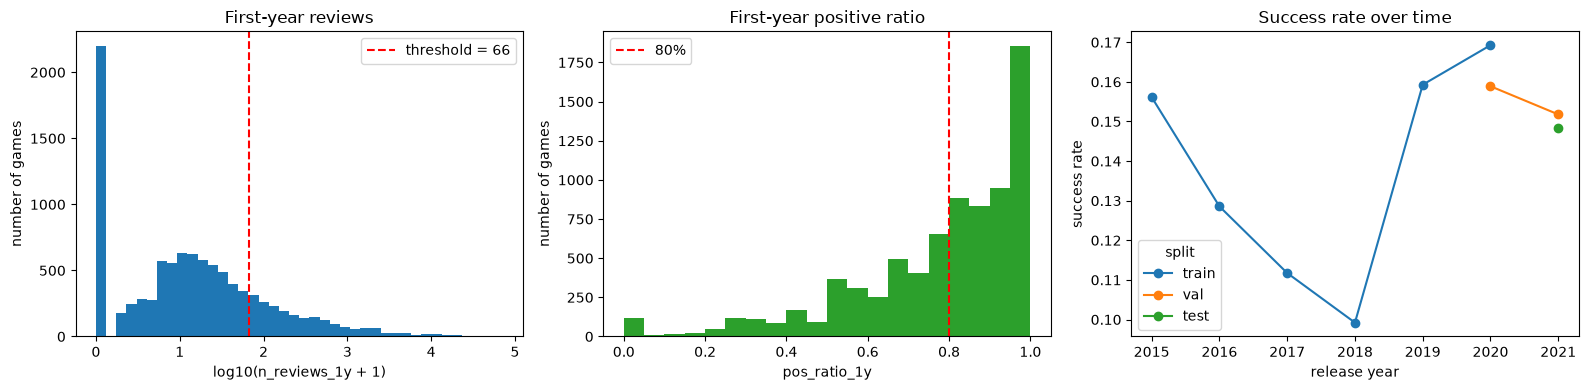

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# (a) first-year review counts (log scale) with the threshold
ax = axes[0]
ax.hist(np.log10(df['n_reviews_1y'] + 1), bins=40, color='tab:blue')
ax.axvline(np.log10(THRESHOLD + 1), color='red', ls='--', label=f'threshold = {THRESHOLD:g}')
ax.set(xlabel='log10(n_reviews_1y + 1)', ylabel='number of games', title='First-year reviews')
ax.legend()

# (b) first-year positive ratio (games with >= 1 review)
ax = axes[1]
ax.hist(df['pos_ratio_1y'].dropna(), bins=20, color='tab:green')
ax.axvline(MIN_POS_RATIO, color='red', ls='--', label=f'{MIN_POS_RATIO:.0%}')
ax.set(xlabel='pos_ratio_1y', ylabel='number of games', title='First-year positive ratio')
ax.legend()

# (c) success rate by release year, coloured by split
ax = axes[2]
by_year = df.groupby([df['release_date'].dt.year, 'split'])['success'].mean().unstack()
by_year[[c for c in ['train', 'val', 'test'] if c in by_year]].plot(ax=ax, marker='o')
ax.set(xlabel='release year', ylabel='success rate', title='Success rate over time')
plt.tight_layout()
plt.show()

## 8. Why the threshold is computed on train only

If the threshold were computed on all games, the label of every training game would depend on the review counts of validation and test games (future games). The comparison below shows how much the threshold and the positive rates change.

In [10]:
thr_all = float(df['n_reviews_1y'].quantile(TOP_QUANTILE))
leaky = ((df['n_reviews_1y'] >= thr_all) & (df['pos_ratio_1y'].fillna(0) >= MIN_POS_RATIO)).astype('int8')
print(f'threshold train-only = {THRESHOLD:g} | threshold on all data (leaky) = {thr_all:g}')
print(pd.DataFrame({'pos_rate_train_threshold': df.groupby('split')['success'].mean(),
                    'pos_rate_all_data_threshold': leaky.groupby(df['split']).mean()}).round(4))
print(f'labels that change: {(leaky != df["success"]).sum()} games')

threshold train-only = 66 | threshold on all data (leaky) = 69
       pos_rate_train_threshold  pos_rate_all_data_threshold
split                                                       
test                     0.1485                       0.1438
train                    0.1319                       0.1284
val                      0.1568                       0.1534
labels that change: 36 games


## 9. Save

In [11]:
out_cols = ['app_id', 'release_date', 'n_reviews_1y', 'pos_ratio_1y',
            'n_reviews_prerelease', 'success', 'split']
df[out_cols].to_parquet(PROC / 'target.parquet', index=False)

info = {'threshold_n_reviews_1y': THRESHOLD, 'top_quantile': TOP_QUANTILE,
        'min_pos_ratio': MIN_POS_RATIO, 'horizon_days': HORIZON_DAYS,
        'review_data_start': str(DATA_START.date()), 'review_data_end': str(DATA_END.date()),
        'cut_val': str(cut_val.date()), 'cut_test': str(cut_test.date()),
        'population_filter': filt_report,
        'split_summary': json.loads(split_summary.to_json(orient='index', date_format='iso')),
        'never_use_as_features': ['n_reviews_1y', 'pos_ratio_1y', 'n_reviews_prerelease']}
(PROC / 'target_info.json').write_text(json.dumps(info, indent=2, default=str))
print(f'saved {PROC / "target.parquet"} ({len(df)} games) and target_info.json')

saved ..\data\processed\target.parquet (10000 games) and target_info.json
